# Proposal UTS Pembelajaran Mesin 2026 — Kelompok 08 · PT Sun Suka Abadi
**Prediksi Dini Keterlambatan Keberangkatan Kargo Ekspor Garmen Berbasis Data ERP NTIS**
**(XGBoost / LightGBM + Optuna TPE + Kalibrasi Ambang Batas Berbasis Biaya dan Kapasitas)**

| | |
|---|---|
| Tim | Muhamad Adif Rizal (12250157) · Fajar Kusumadinata (12250126) · Hermi Kuswarini (12250163) |
| Kelas | KG.043.10.A (12.8A.10) — Dosen: Dr. Irwansyah Saputra, M.Kom. |
| Tugas ML | Klasifikasi biner `Delivery Status` (0 = On-Time, 1 = Delayed) |

**Cara menjalankan:** `Runtime → Run all`, lalu unggah `NTIS_DATASET.csv` saat diminta (sel 2).
Seluruh angka pada naskah Proposal UTS (Bab III) dihasilkan oleh notebook ini. Waktu jalan ±5–8 menit.

**Prinsip zero data leakage:** imputasi, scaling, encoding, dan SMOTE hanya di-*fit* pada data latih di setiap
fold (di dalam `Pipeline`); data uji (20%) hanya dipakai **satu kali** setelah model dan threshold dikunci.

## 1. Instalasi pustaka
Versi dikunci agar hasil identik dengan naskah. Bila Colab meminta *Restart session*, klik lalu lanjut dari sel 2.

In [1]:
!pip install -q optuna==5.0.0 xgboost==3.4.1 lightgbm==4.6.0 scikit-learn==1.9.1 imbalanced-learn

(instalasi dilewati pada eksekusi lokal)


## 2. Data — unggah `NTIS_DATASET.csv`
Dataset adalah ekspor ERP **Nobland Total Information System (NTIS)** PT Sun Suka Abadi. Data internal
perusahaan, tidak dipublikasikan di repositori; diakses legal melalui anggota tim (Asst. Manager).

In [2]:
import os
if not os.path.exists("NTIS_DATASET.csv"):
    try:
        from google.colab import files
        files.upload()                                   # pilih NTIS_DATASET.csv dari komputer
    except ImportError:
        raise FileNotFoundError("Letakkan NTIS_DATASET.csv di folder kerja notebook ini.")
print("Data siap:", os.path.getsize("NTIS_DATASET.csv"), "byte")

Data siap: 403064 byte


## 3. Modul rekayasa fitur & preprocessing (`ntis_prep.py`)
Ditulis sebagai modul karena model `.joblib` membutuhkan fungsi `build_features` saat dimuat ulang.

In [3]:
%%writefile ntis_prep.py
"""
ntis_prep.py — Kelompok 08 (PT Sun Suka Abadi) — Proposal UTS Pembelajaran Mesin 2026
Modul rekayasa fitur & preprocessing. File ini WAJIB berada di folder yang sama dengan
model .joblib karena fungsi build_features dipanggil di dalam pipeline deployment.
"""
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, TargetEncoder

TARGET = "Delivery Status"
RAW_INPUT = ["Contrac date", "Waktu Penutupan Gudang", "STYLE", "QTYO", "Dest", "Smode", "Season", "FWD"]
FWD_KEEP = ["APL LOGISTICS", "UPS", "EXPEDITOR INDONESIA", "APEX", "EFL GLOBAL"]
SEASON_KEEP = ["2026 FAL", "2026 HOL"]

# Set fitur final UTS (7 fitur, tanpa Order_Month -> bebas risiko kebocoran temporal)
NUM_COLS = ["QTYO", "Closing_Month"]
CAT_COLS = ["Smode", "Dest", "FWD", "Season_Group"]
TE_COLS = ["STYLE"]
FEATURES = NUM_COLS + CAT_COLS + TE_COLS
# Set fitur Tugas 04-06 (8 fitur) -> hanya untuk ablasi
NUM_COLS_T06 = ["QTYO", "Order_Month", "Closing_Month"]


def load_raw(path):
    """Membaca CSV ekspor ERP NTIS (2 baris keterangan di atas header)."""
    df = pd.read_csv(path, skiprows=2)
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    return df[df["PO"].notna()].reset_index(drop=True)


def labeled_subset(df):
    """Label final hanya untuk kargo yang sudah memiliki TANGGAL KAPAL BERANGKAT."""
    return df[df["TANGGAL KAPAL BERANGKAT"].notna()].reset_index(drop=True)


def build_features(df):
    """Mengubah kolom mentah ERP menjadi fitur pra-keberangkatan (tanpa kolom pasca-kejadian)."""
    out = pd.DataFrame(index=df.index)
    out["QTYO"] = pd.to_numeric(df["QTYO"], errors="coerce")
    out["Order_Month"] = pd.to_datetime(df["Contrac date"], errors="coerce").dt.month   # ablasi saja
    out["Closing_Month"] = pd.to_datetime(df["Waktu Penutupan Gudang"], errors="coerce").dt.month
    out["Smode"] = df["Smode"].astype("string")
    out["Dest"] = df["Dest"].astype("string")
    fwd = df["FWD"].astype("string")
    out["FWD"] = fwd.where(fwd.isin(FWD_KEEP), "lainnya")            # forwarder jarang -> 'lainnya'
    season = df["Season"].astype("string")
    out["Season_Group"] = season.where(season.isin(SEASON_KEEP), "lainnya")
    out["STYLE"] = df["STYLE"].astype("string")
    return out


def make_preprocessor(num_cols=NUM_COLS, seed=42):
    """ColumnTransformer: dipelajari HANYA dari data latih di setiap fold (dibungkus Pipeline)."""
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    te = TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=seed))
    return ColumnTransformer([("num", num, list(num_cols)), ("cat", cat, CAT_COLS), ("te", te, TE_COLS)],
                             remainder="drop", verbose_feature_names_out=False)


def make_imputer(num_cols=NUM_COLS):
    """Imputer awal (untuk skenario SMOTENC yang tidak menerima nilai hilang); output DataFrame."""
    ct = ColumnTransformer([("num", SimpleImputer(strategy="median"), list(num_cols)),
                            ("cat", SimpleImputer(strategy="most_frequent"), CAT_COLS + TE_COLS)],
                           remainder="drop", verbose_feature_names_out=False)
    return ct.set_output(transform="pandas")

Writing ntis_prep.py


## 4. Impor, konfigurasi, dan versi pustaka

In [4]:
import json, time, warnings, platform
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, xgboost, lightgbm, optuna, imblearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, brier_score_loss)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import ntis_prep as npp

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
VERSIONS = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "lightgbm": lightgbm.__version__, "optuna": optuna.__version__, "imbalanced-learn": imblearn.__version__,
            "pandas": pd.__version__, "numpy": np.__version__}
print(VERSIONS)
RES = {"versions": VERSIONS}          # semua hasil numerik dikumpulkan di sini -> results/uts_results.json

{'python': '3.13.17', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'optuna': '5.0.0', 'imbalanced-learn': '0.15.dev0', 'pandas': '3.0.5', 'numpy': '2.5.3'}


## 5. Pemahaman data & rekonsiliasi label (CRISP-DM: Data Understanding)
Dari 3.849 baris ekspor, hanya kargo yang sudah memiliki `TANGGAL KAPAL BERANGKAT` yang berlabel final.

In [5]:
raw = npp.load_raw("NTIS_DATASET.csv")
lab = npp.labeled_subset(raw)
y_all = lab[npp.TARGET].astype(int)
RES["data"] = {"n_raw": len(raw), "n_cols_raw": raw.shape[1], "n_labeled": len(lab), "n_pending": len(raw) - len(lab),
               "n_delayed": int(y_all.sum()), "n_ontime": int((y_all == 0).sum()),
               "pct_delayed": round(float(y_all.mean() * 100), 2),
               "contract_range": [str(pd.to_datetime(raw["Contrac date"]).min().date()),
                                  str(pd.to_datetime(raw["Contrac date"]).max().date())],
               "departure_range_labeled": [str(pd.to_datetime(lab["Berangkat pabrik"]).min().date()),
                                           str(pd.to_datetime(lab["Berangkat pabrik"]).max().date())],
               "n_style": int(lab.STYLE.nunique()), "missing_season": int(raw["Season"].isna().sum())}
print(json.dumps(RES["data"], indent=1))
print(f"Rasio ketimpangan On-Time : Delayed = {RES['data']['n_ontime']/RES['data']['n_delayed']:.2f} : 1")

{
 "n_raw": 3849,
 "n_cols_raw": 13,
 "n_labeled": 3143,
 "n_pending": 706,
 "n_delayed": 375,
 "n_ontime": 2768,
 "pct_delayed": 11.93,
 "contract_range": [
  "2026-06-01",
  "2026-12-28"
 ],
 "departure_range_labeled": [
  "2026-05-22",
  "2026-10-16"
 ],
 "n_style": 210,
 "missing_season": 1
}
Rasio ketimpangan On-Time : Delayed = 7.38 : 1


### 5.1 Audit kebocoran data (target & temporal leakage)
* `Buffer_Waktu_Gudang` (cut-off − berangkat pabrik) adalah **definisi label** → dibuang (Tugas 03).
* `Contrac date` tercatat **setelah** keberangkatan pabrik pada sebagian besar baris → `Order_Month` berisiko
  bocor secara temporal (catatan dosen Tugas 04) → diuji lewat ablasi pada Bagian 11.

In [6]:
d = lab.copy()
for c in ["Contrac date", "Berangkat pabrik", "Waktu Penutupan Gudang"]:
    d[c] = pd.to_datetime(d[c])
buffer = (d["Waktu Penutupan Gudang"] - d["Berangkat pabrik"]).dt.days
RES["leakage_audit"] = {
    "buffer_neg_equals_label": float(((buffer < 0).astype(int) == y_all).mean()),
    "contract_after_departure_share": round(float((d["Contrac date"] > d["Berangkat pabrik"]).mean()), 4),
    "label_inconsistent_rows": int(((buffer < 0) & (y_all == 0)).sum()),
    "delayed_1day": int(((buffer == -1) & (y_all == 1)).sum())}
print(json.dumps(RES["leakage_audit"], indent=1))

{
 "buffer_neg_equals_label": 0.9786827871460388,
 "contract_after_departure_share": 0.8896,
 "label_inconsistent_rows": 67,
 "delayed_1day": 237
}


## 6. Rekayasa fitur & Exploratory Data Analysis (Gambar 3.2)
Fitur final (7): `QTYO`, `Closing_Month`, `Smode`, `Dest`, `FWD`, `Season_Group`, `STYLE`.

Dest=USA           -0.055
Dest=Canada         0.115
QTYO                0.138
Season=HOL          0.180
Smode=BOAT          0.213
Closing_Month       0.230
FWD=APL             0.231
Order_Month*        0.252
STYLE rate (LOO)    0.326
Delayed (target)    1.000
Name: Delayed (target), dtype: float64


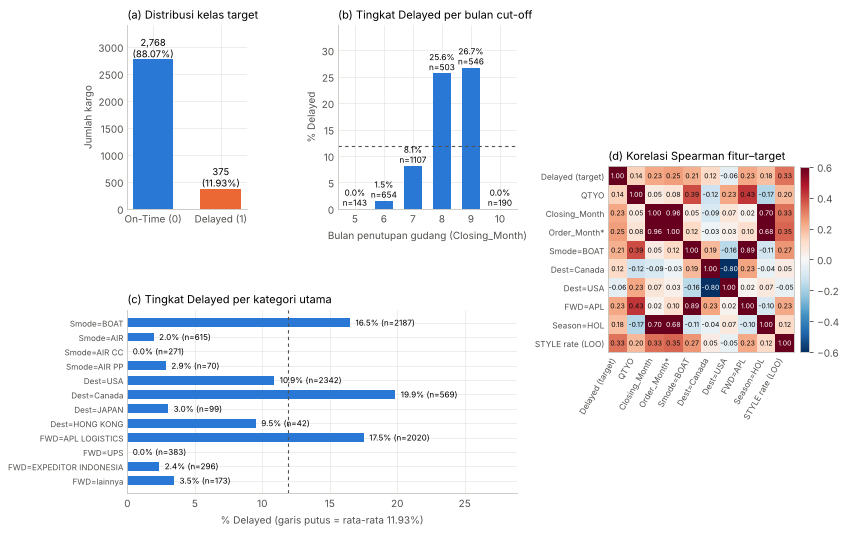

In [7]:
X_all = npp.build_features(lab)
eda = X_all.assign(y=y_all.values)
desc = {"QTYO": eda.QTYO.describe().round(1).to_dict(),
        "Closing_Month": eda.Closing_Month.value_counts().sort_index().to_dict()}
for c in ["Smode", "Dest", "FWD", "Season_Group"]:
    desc[c] = (eda.groupby(c)["y"].agg(["size", "mean"]).sort_values("size", ascending=False)
               .round(4).to_dict("index"))
desc["delayed_by_closing_month"] = eda.groupby("Closing_Month")["y"].mean().round(4).to_dict()
desc["style_freq_le5"] = int((eda.STYLE.value_counts() <= 5).sum())
RES["eda"] = desc

# Korelasi (Spearman) antara fitur numerik, indikator kategori utama, dan target
corr_df = pd.DataFrame({"Delayed (target)": eda.y, "QTYO": eda.QTYO, "Closing_Month": eda.Closing_Month,
                        "Order_Month*": eda.Order_Month,
                        "Smode=BOAT": (eda.Smode == "BOAT").astype(int), "Dest=Canada": (eda.Dest == "Canada").astype(int),
                        "Dest=USA": (eda.Dest == "USA").astype(int), "FWD=APL": (eda.FWD == "APL LOGISTICS").astype(int),
                        "Season=HOL": (eda.Season_Group == "2026 HOL").astype(int),
                        "STYLE rate (LOO)": (eda.groupby("STYLE")["y"].transform("sum") - eda.y) /
                                            (eda.groupby("STYLE")["y"].transform("size") - 1).replace(0, np.nan)})
CORR = corr_df.corr(method="spearman").round(3)
RES["eda"]["corr_with_target"] = CORR["Delayed (target)"].drop("Delayed (target)").to_dict()

SURF, INK, INK2, GRID = "#ffffff", "#0b0b0b", "#52514e", "#e6e5e0"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlelocation": "left", "axes.titlesize": 10, "savefig.dpi": 300})


def style_ax(ax):
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True); ax.tick_params(length=0)


fig = plt.figure(figsize=(11, 7.6))
gs = fig.add_gridspec(2, 3, width_ratios=[0.8, 1.2, 1.35], height_ratios=[1, 1], wspace=0.55, hspace=0.55)
a = fig.add_subplot(gs[0, 0])
cnt = [RES["data"]["n_ontime"], RES["data"]["n_delayed"]]
a.bar(["On-Time (0)", "Delayed (1)"], cnt, color=[C1, C2], width=0.6)
for i, v in enumerate(cnt):
    a.text(i, v + 40, f"{v:,}\n({v/sum(cnt)*100:.2f}%)", ha="center", fontsize=8.5)
a.set_ylim(0, 3400); a.set_title("(a) Distribusi kelas target"); a.set_ylabel("Jumlah kargo"); style_ax(a)
b = fig.add_subplot(gs[0, 1])
rate = eda.groupby("Closing_Month")["y"].agg(["mean", "size"])
b.bar(rate.index.astype(str), rate["mean"] * 100, color=C1, width=0.6)
for i, (m, s) in enumerate(zip(rate["mean"], rate["size"])):
    b.text(i, m * 100 + 0.6, f"{m*100:.1f}%\nn={s}", ha="center", fontsize=7.5)
b.axhline(y_all.mean() * 100, color=INK2, lw=1, ls=(0, (3, 3)))
b.set_ylim(0, max(rate["mean"] * 100) + 8)
b.set_xlabel("Bulan penutupan gudang (Closing_Month)"); b.set_ylabel("% Delayed")
b.set_title("(b) Tingkat Delayed per bulan cut-off"); style_ax(b)
c = fig.add_subplot(gs[:, 2])
im = c.imshow(CORR.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
c.set_xticks(range(len(CORR))); c.set_xticklabels(CORR.columns, rotation=60, ha="right", fontsize=7.5)
c.set_yticks(range(len(CORR))); c.set_yticklabels(CORR.index, fontsize=7.5)
for i in range(len(CORR)):
    for j in range(len(CORR)):
        v = CORR.values[i, j]
        c.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.2, color="white" if abs(v) > 0.45 else INK)
c.set_title("(d) Korelasi Spearman fitur–target"); c.tick_params(length=0)
fig.colorbar(im, ax=c, fraction=0.046, pad=0.03)
dd = fig.add_subplot(gs[1, :2])
grp = []
for col, lbl in [("Smode", "Smode"), ("Dest", "Dest"), ("FWD", "FWD")]:
    g = eda.groupby(col)["y"].agg(["mean", "size"]).sort_values("size", ascending=False).head(4)
    for k, r in g.iterrows():
        grp.append((f"{lbl}={k}", r["mean"] * 100, int(r["size"])))
grp = grp[::-1]
dd.barh([g[0] for g in grp], [g[1] for g in grp], color=C1, height=0.62)
for i, g in enumerate(grp):
    dd.text(g[1] + 0.4, i, f"{g[1]:.1f}% (n={g[2]})", va="center", fontsize=7.3)
dd.axvline(y_all.mean() * 100, color=INK2, lw=1, ls=(0, (3, 3)))
dd.set_xlabel("% Delayed (garis putus = rata-rata 11.93%)"); dd.set_title("(c) Tingkat Delayed per kategori utama")
dd.tick_params(axis="y", labelsize=7.3); style_ax(dd); dd.set_xlim(0, max(g[1] for g in grp) + 9)
fig.savefig("figures/gambar3_2_eda.png", bbox_inches="tight", facecolor=SURF); plt.show()
print(CORR["Delayed (target)"].sort_values())

## 7. Skema eksperimen: Train–Test Split 80:20 & Stratified 5-Fold CV
Split dikunci dengan `random_state=42`; proporsi kelas minoritas dijaga identik di latih, uji, dan setiap fold.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
RES["split"] = {"n_train": len(X_train), "n_test": len(X_test), "train_delayed": int(y_train.sum()),
                "test_delayed": int(y_test.sum()),
                "fold_delayed_pct": [round(float(y_train.iloc[v].mean() * 100), 2) for _, v in skf.split(X_train, y_train)]}
print(json.dumps(RES["split"], indent=1))
SCORING = {"ap": "average_precision", "roc_auc": "roc_auc", "f1_macro": "f1_macro",
           "recall": "recall", "precision": "precision"}


def cv_eval(pipe, X=X_train, y=y_train):
    """Stratified 5-Fold CV; seluruh preprocessing di-fit ulang di setiap fold (di dalam pipe)."""
    r = cross_validate(pipe, X, y, cv=skf, scoring=SCORING, n_jobs=-1, return_train_score=True)
    out = {f"cv_{k}": float(r[f"test_{k}"].mean()) for k in SCORING}
    out.update({f"cv_{k}_sd": float(r[f"test_{k}"].std()) for k in SCORING})
    out["train_ap"] = float(r["train_ap"].mean())
    return out


def test_eval(pipe, thr=0.5, X=X_test, y=y_test):
    p = pipe.predict_proba(X)[:, 1]; yp = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, yp), "precision": precision_score(y, yp, zero_division=0),
            "recall": recall_score(y, yp), "f1": f1_score(y, yp, zero_division=0),
            "f1_macro": f1_score(y, yp, average="macro"), "roc_auc": roc_auc_score(y, p),
            "pr_auc": average_precision_score(y, p), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

{
 "n_train": 2514,
 "n_test": 629,
 "train_delayed": 300,
 "test_delayed": 75,
 "fold_delayed_pct": [
  11.93,
  11.93,
  11.93,
  11.93,
  11.95
 ]
}


## 8. Pipeline pra-pemrosesan bebas kebocoran (`imblearn.pipeline.Pipeline`)
Urutan di dalam setiap fold: **Imputer → (SMOTENC, opsional) → RobustScaler + One-Hot + TargetEncoder → model**.
`SMOTENC` dipakai (bukan SMOTE biasa) karena 5 dari 7 fitur kategorikal; sampel sintetis hanya dibuat dari data
latih fold tersebut, sehingga data validasi/uji tetap murni.

In [9]:
def make_pipeline(model, smote=False, num_cols=npp.NUM_COLS):
    steps = []
    if smote:
        steps += [("impute", npp.make_imputer(num_cols)),
                  ("smote", SMOTENC(categorical_features=npp.CAT_COLS + npp.TE_COLS, random_state=SEED))]
    steps += [("prep", npp.make_preprocessor(num_cols, SEED)), ("clf", model)]
    return ImbPipeline(steps)


XGB_BASE = dict(objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1)
LGB_BASE = dict(objective="binary", random_state=SEED, n_jobs=1, verbose=-1)
print(make_pipeline(XGBClassifier(**XGB_BASE), smote=True))

Pipeline(steps=[('impute',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['QTYO', 'Closing_Month']),
                                                 ('cat',
                                                  SimpleImputer(strategy='most_frequent'),
                                                  ['Smode', 'Dest', 'FWD',
                                                   'Season_Group', 'STYLE'])],
                                   verbose_feature_names_out=False)),
                ('smote',
                 SMOTENC(categorical_features=['Smode', 'Dest', 'FWD',
                                               'Season_Group', 'STYLE'],
                         random_state=...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               impor

## 9. RQ1 — Pengaruh strategi penanganan ketimpangan kelas (XGBoost default)
Tiga skenario dibandingkan dengan CV yang sama: tanpa penanganan, *class weighting* (`scale_pos_weight` = 7.38),
dan SMOTENC di dalam fold.

In [10]:
spw = float((y_train == 0).sum() / (y_train == 1).sum())
imb = {}
for name, pipe in {"Tanpa penanganan": make_pipeline(XGBClassifier(**XGB_BASE)),
                   "Class weight (spw=%.2f)" % spw: make_pipeline(XGBClassifier(**XGB_BASE, scale_pos_weight=spw)),
                   "SMOTENC di dalam fold": make_pipeline(XGBClassifier(**XGB_BASE), smote=True)}.items():
    imb[name] = cv_eval(pipe)
IMB = pd.DataFrame(imb).T[["cv_ap", "cv_roc_auc", "cv_f1_macro", "cv_recall", "cv_precision"]].round(4)
RES["rq1_imbalance"] = imb
IMB

,cv_ap,cv_roc_auc,cv_f1_macro,cv_recall,cv_precision
Tanpa penanganan,0.5136,0.8795,0.6908,0.3833,0.5336
Class weight (spw=7.38),0.4923,0.8738,0.7017,0.5700,0.4261
SMOTENC di dalam fold,0.5311,0.8725,0.7144,0.5833,0.4506


## 10. RQ2 — Baseline vs Ensemble (parameter default)
Baseline: Logistic Regression, Decision Tree. Ensemble: Random Forest (bagging), LightGBM & XGBoost (boosting).

In [11]:
MODELS = {"Logistic Regression (Baseline)": LogisticRegression(max_iter=2000),
          "Decision Tree (Baseline)": DecisionTreeClassifier(random_state=SEED),
          "Random Forest (Ensemble)": RandomForestClassifier(random_state=SEED, n_jobs=1),
          "LightGBM (Ensemble)": LGBMClassifier(**LGB_BASE),
          "XGBoost (Ensemble)": XGBClassifier(**XGB_BASE)}
cmp, fitted_default, p_test_default = {}, {}, {}
for name, m in MODELS.items():
    pipe = make_pipeline(m)
    cv = cv_eval(pipe)
    fitted_default[name] = clone(pipe).fit(X_train, y_train)
    p_test_default[name] = fitted_default[name].predict_proba(X_test)[:, 1]
    cmp[name] = {**cv, **{f"test_{k}": v for k, v in test_eval(fitted_default[name]).items()}}
CMP = pd.DataFrame(cmp).T
RES["rq2_models"] = cmp
CMP[["test_accuracy", "test_precision", "test_recall", "test_f1_macro", "test_roc_auc", "test_pr_auc", "cv_ap", "cv_roc_auc"]].round(4)

,test_accuracy,test_precision,test_recall,test_f1_macro,test_roc_auc,test_pr_auc,cv_ap,cv_roc_auc
Logistic Regression (Baseline),0.8871,0.6111,0.1467,0.5878,0.8411,0.4088,0.4478,0.8342
Decision Tree (Baseline),0.8601,0.4217,0.4667,0.6815,0.6909,0.2652,0.2360,0.6697
Random Forest (Ensemble),0.8824,0.5088,0.3867,0.6868,0.8542,0.4995,0.5138,0.8650
LightGBM (Ensemble),0.8792,0.4906,0.3467,0.6695,0.8964,0.4994,0.5134,0.8855
XGBoost (Ensemble),0.8744,0.4583,0.2933,0.6441,0.8781,0.4892,0.5136,0.8795


## 11. Ablasi kebocoran temporal: 8 fitur (dengan `Order_Month`) vs 7 fitur vs tanpa fitur kalender
Menjawab catatan dosen Tugas 04 ("potensi bias temporal pada fitur Order_Month").

In [12]:
abl = {}
for name, num in {"8 fitur (Tugas 04–06, + Order_Month)": npp.NUM_COLS_T06,
                  "7 fitur (final UTS, tanpa Order_Month)": npp.NUM_COLS,
                  "6 fitur (tanpa fitur kalender)": ["QTYO"]}.items():
    pipe = make_pipeline(XGBClassifier(**XGB_BASE), num_cols=num)
    abl[name] = {**cv_eval(pipe), **{f"test_{k}": v for k, v in test_eval(clone(pipe).fit(X_train, y_train)).items()}}
RES["ablation_default_xgb"] = abl
pd.DataFrame(abl).T[["cv_ap", "cv_roc_auc", "test_pr_auc", "test_roc_auc"]].round(4)

,cv_ap,cv_roc_auc,test_pr_auc,test_roc_auc
"8 fitur (Tugas 04–06, + Order_Month)",0.5721,0.8924,0.4837,0.8825
"7 fitur (final UTS, tanpa Order_Month)",0.5136,0.8795,0.4892,0.8781
6 fitur (tanpa fitur kalender),0.4559,0.8308,0.4010,0.8314


## 12. RQ3a — Optimasi hiperparameter Optuna (TPE, 100 trial, Stratified 5-Fold CV)
Objective: **mean CV Average Precision (PR-AUC)** — metrik yang tidak bergantung threshold, sehingga kualitas
model dan pemilihan threshold (Bagian 14) tidak tercampur. F1-Macro dan ROC-AUC tetap dicatat per trial.
Empat studi terpisah: {XGBoost, LightGBM} × {class weighting, SMOTENC di dalam fold}, 100 trial masing-masing.

In [13]:
def build_tuned(family, params, smote=False):
    p = dict(params); smooth = p.pop("te_smooth", "auto")
    if family == "lgb":
        p.setdefault("subsample_freq", 1)        # bagging LightGBM aktif (subsample hanya berlaku bila freq > 0)
    model = XGBClassifier(**XGB_BASE, **p) if family == "xgb" else LGBMClassifier(**LGB_BASE, **p)
    pipe = make_pipeline(model, smote=smote)
    pipe.set_params(prep__te__smooth=smooth)
    return pipe


def space(t, family):
    p = {"n_estimators": t.suggest_int("n_estimators", 50, 600),
         "max_depth": t.suggest_int("max_depth", 3, 10),
         "learning_rate": t.suggest_float("learning_rate", 0.01, 0.3, log=True),
         "subsample": t.suggest_float("subsample", 0.6, 1.0),
         "colsample_bytree": t.suggest_float("colsample_bytree", 0.6, 1.0),
         "reg_alpha": t.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
         "reg_lambda": t.suggest_float("reg_lambda", 0.1, 50.0, log=True),
         "scale_pos_weight": t.suggest_categorical("scale_pos_weight", [1.0, 2.72, 7.38]),   # bobot kelas
         "te_smooth": t.suggest_categorical("te_smooth", ["auto", 10.0, 50.0])}
    if family == "xgb":
        p.update(min_child_weight=t.suggest_int("min_child_weight", 1, 10), gamma=t.suggest_float("gamma", 0.0, 2.0))
    else:
        p.update(num_leaves=t.suggest_int("num_leaves", 8, 128, log=True),
                 min_child_samples=t.suggest_int("min_child_samples", 5, 100, log=True))
    return p


def make_objective(family, smote):
    def objective(t):
        r = cross_validate(build_tuned(family, space(t, family), smote), X_train, y_train, cv=skf, n_jobs=-1,
                           scoring={"ap": "average_precision", "f1_macro": "f1_macro", "roc_auc": "roc_auc"})
        t.set_user_attr("cv_f1_macro", float(r["test_f1_macro"].mean()))
        t.set_user_attr("cv_roc_auc", float(r["test_roc_auc"].mean()))
        return float(r["test_ap"].mean())
    return objective


# Empat studi terpisah (100 trial masing-masing): {XGBoost, LightGBM} x {class weighting, SMOTENC di dalam fold}
STUDY_DEF = {"xgb_cw": ("xgb", False), "xgb_smote": ("xgb", True), "lgb_cw": ("lgb", False), "lgb_smote": ("lgb", True)}
STUDIES = {}
for key, (fam_, smote_) in STUDY_DEF.items():
    st = optuna.create_study(direction="maximize", study_name=key,
                             sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=10))
    t0 = time.time(); st.optimize(make_objective(fam_, smote_), n_trials=100); el = time.time() - t0
    STUDIES[key] = st
    tr = st.trials_dataframe(attrs=("number", "value", "params", "user_attrs"))
    tr.to_csv(f"results/optuna_trials_{key}.csv", index=False)
    try:
        imp = optuna.importance.get_param_importances(st, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
    except Exception:
        imp = optuna.importance.get_param_importances(st)
    RES[f"optuna_{key}"] = {"best_value": st.best_value, "best_trial": st.best_trial.number, "best_params": st.best_params,
                            "elapsed_s": round(el, 1), "importance": {k: float(v) for k, v in imp.items()},
                            "n_beat_default": int((tr["value"] > cmp[("XGBoost" if fam_ == "xgb" else "LightGBM") + " (Ensemble)"]["cv_ap"]).sum()),
                            "top5": tr.sort_values("value", ascending=False).head(5)[["number", "value"]].to_dict("records")}
    print(f"{key:10s} best CV AP {st.best_value:.4f} (trial #{st.best_trial.number}, {el:.0f} s)", st.best_params)

xgb_cw     best CV AP 0.5805 (trial #72, 34 s) {'n_estimators': 52, 'max_depth': 9, 'learning_rate': 0.016184607427223552, 'subsample': 0.869083292907327, 'colsample_bytree': 0.7146049479666324, 'reg_alpha': 0.019162081764103295, 'reg_lambda': 0.10373568023821693, 'scale_pos_weight': 7.38, 'te_smooth': 'auto', 'min_child_weight': 6, 'gamma': 0.27140794695734277}
xgb_smote  best CV AP 0.5546 (trial #98, 86 s) {'n_estimators': 241, 'max_depth': 6, 'learning_rate': 0.029691356094957114, 'subsample': 0.7922390591777406, 'colsample_bytree': 0.7210317275775995, 'reg_alpha': 0.11491385409883167, 'reg_lambda': 0.2745652079565649, 'scale_pos_weight': 7.38, 'te_smooth': 'auto', 'min_child_weight': 5, 'gamma': 0.15613059769108245}
lgb_cw     best CV AP 0.5637 (trial #92, 40 s) {'n_estimators': 223, 'max_depth': 10, 'learning_rate': 0.017970601201977993, 'subsample': 0.9460253395140564, 'colsample_bytree': 0.8319289891411366, 'reg_alpha': 0.04364857814918274, 'reg_lambda': 0.5896422791771393, 'sca

## 13. Before vs After Tuning & pemilihan model final (berdasarkan CV AP, bukan data uji)

In [14]:
LABEL = {"xgb_cw": "XGBoost Optuna (class weight)", "xgb_smote": "XGBoost Optuna (SMOTENC)",
         "lgb_cw": "LightGBM Optuna (class weight)", "lgb_smote": "LightGBM Optuna (SMOTENC)"}
ba, pipes = {"XGBoost default": cmp["XGBoost (Ensemble)"], "LightGBM default": cmp["LightGBM (Ensemble)"]}, {}
for key, (fam_, smote_) in STUDY_DEF.items():
    tuned = build_tuned(fam_, STUDIES[key].best_params, smote_)
    pipes[key] = clone(tuned).fit(X_train, y_train)
    ba[LABEL[key]] = {**cv_eval(tuned), **{f"test_{k}": v for k, v in test_eval(pipes[key]).items()}}
FINAL_KEY = max(STUDY_DEF, key=lambda k: ba[LABEL[k]]["cv_ap"])          # aturan seleksi: CV AP tertinggi
FINAL_NAME, final_pipe = LABEL[FINAL_KEY], pipes[FINAL_KEY]
fam = STUDY_DEF[FINAL_KEY][0]
RES["before_after"] = ba; RES["final_model"] = FINAL_NAME; RES["final_key"] = FINAL_KEY
BA = pd.DataFrame(ba).T[["cv_ap", "cv_roc_auc", "cv_f1_macro", "test_f1_macro", "test_roc_auc", "test_recall", "test_pr_auc"]]
print("MODEL FINAL (CV AP tertinggi):", FINAL_NAME)
BA.round(4)

MODEL FINAL (CV AP tertinggi): XGBoost Optuna (class weight)


,cv_ap,cv_roc_auc,cv_f1_macro,test_f1_macro,test_roc_auc,test_recall,test_pr_auc
XGBoost default,0.5136,0.8795,0.6908,0.6441,0.8781,0.2933,0.4892
LightGBM default,0.5134,0.8855,0.6990,0.6695,0.8964,0.3467,0.4994
XGBoost Optuna (class weight),0.5805,0.8965,0.6809,0.7079,0.9042,0.8267,0.5354
XGBoost Optuna (SMOTENC),0.5546,0.8833,0.6785,0.6949,0.9008,0.8267,0.5529
LightGBM Optuna (class weight),0.5637,0.8959,0.6764,0.6877,0.8979,0.8533,0.5109
LightGBM Optuna (SMOTENC),0.5574,0.8844,0.6933,0.6991,0.9038,0.8000,0.5829


## 14. Kalibrasi ambang batas (Decision Threshold Tuning) — dipilih dari prediksi OOF data latih
Kebijakan: **minimalkan biaya harapan C(t) = c_FN·FN(t) + c_FP·FP(t)** pada prediksi out-of-fold. Satu FN (kargo
terlambat tanpa peringatan → gagal kapal, rebooking, demurrage/kirim udara) jauh lebih mahal daripada satu FP
(satu verifikasi manual PPIC). Asumsi kerja: c_FN ≥ 5·c_FP; kepekaan terhadap rasio 1:1 s.d. 10:1 dilaporkan.
Tabel 0.30–0.70 dihitung pada data uji hanya untuk pelaporan (data uji tidak dipakai untuk memilih).

In [15]:
oof = cross_val_predict(clone(final_pipe), X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
share = np.array([(oof >= t).mean() for t in grid])
f1_oof = np.array([f1_score(y_train, (oof >= t).astype(int), zero_division=0) for t in grid])
THR_F1 = float(grid[f1_oof.argmax()])
cost = {}
for ratio in range(1, 11):
    c_ = [ratio * ((oof < t) & (y_train == 1)).sum() + ((oof >= t) & (y_train == 0)).sum() for t in grid]
    cost[f"{ratio}:1"] = float(grid[int(np.argmin(c_))])
THR = cost["5:1"]                                   # ambang terpilih (asumsi c_FN = 5 x c_FP)
THR_CAP = float(grid[np.argmax(share <= 0.20)])     # alternatif bila kapasitas review dibatasi 20% kargo
HI = cost["1:1"]                                    # batas zona prioritas tindakan
p_final = final_pipe.predict_proba(X_test)[:, 1]
rows = []
for t in sorted({0.30, 0.40, 0.50, 0.60, 0.70, THR, THR_CAP}):
    yp = (p_final >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    ypo = (oof >= t).astype(int)
    rows.append({"threshold": t, "precision": precision_score(y_test, yp, zero_division=0),
                 "recall": recall_score(y_test, yp), "f1": f1_score(y_test, yp, zero_division=0),
                 "f1_macro": f1_score(y_test, yp, average="macro"), "FN": int(fn), "FP": int(fp), "TP": int(tp),
                 "flagged": int(tp + fp), "oof_precision": precision_score(y_train, ypo, zero_division=0),
                 "oof_recall": recall_score(y_train, ypo), "oof_flag_share": float(ypo.mean())})
THR_TABLE = pd.DataFrame(rows)
RES["threshold"] = {"selected": THR, "capacity20": THR_CAP, "f1_opt_oof": THR_F1, "cost_opt_oof": cost,
                    "priority_from": HI, "oof_flag_share_selected": float((oof >= THR).mean()),
                    "oof_recall_selected": float(recall_score(y_train, (oof >= THR).astype(int))),
                    "oof_precision_selected": float(precision_score(y_train, (oof >= THR).astype(int))), "table": rows}
print("Threshold terpilih (5:1):", THR, "| kapasitas 20%:", THR_CAP, "| F1-optimal OOF:", THR_F1, "| cost-optimal:", cost)
THR_TABLE.round(4)

Threshold terpilih (5:1): 0.55 | kapasitas 20%: 0.56 | F1-optimal OOF: 0.61 | cost-optimal: {'1:1': 0.69, '2:1': 0.61, '3:1': 0.61, '4:1': 0.57, '5:1': 0.55, '6:1': 0.48, '7:1': 0.48, '8:1': 0.44, '9:1': 0.39, '10:1': 0.39}


,threshold,precision,recall,f1,f1_macro,FN,FP,TP,flagged,oof_precision,oof_recall,oof_flag_share
0,0.30,0.2322,1.0000,0.3769,0.5443,0,248,75,323,0.2266,0.9867,0.5195
1,0.40,0.3202,0.9733,0.4818,0.6587,2,155,73,228,0.2894,0.9000,0.3711
2,0.50,0.3851,0.8267,0.5254,0.7079,13,99,62,161,0.3506,0.7900,0.2689
3,0.55,0.4153,0.6533,0.5078,0.7093,26,69,49,118,0.4157,0.7233,0.2076
4,0.56,0.4234,0.6267,0.5054,0.7098,28,64,47,111,0.4217,0.7000,0.1981
5,0.60,0.5056,0.6000,0.5488,0.7406,30,44,45,89,0.4986,0.6100,0.1460
6,0.70,0.6429,0.2400,0.3495,0.6458,57,10,18,28,0.7115,0.2467,0.0414


## 15. Evaluasi final pada data uji (sekali pakai): classification report, confusion matrix, ROC & PR

              precision    recall  f1-score   support

 On-Time (0)     0.9491    0.8755    0.9108       554
 Delayed (1)     0.4153    0.6533    0.5078        75

    accuracy                         0.8490       629
   macro avg     0.6822    0.7644    0.7093       629
weighted avg     0.8855    0.8490    0.8627       629



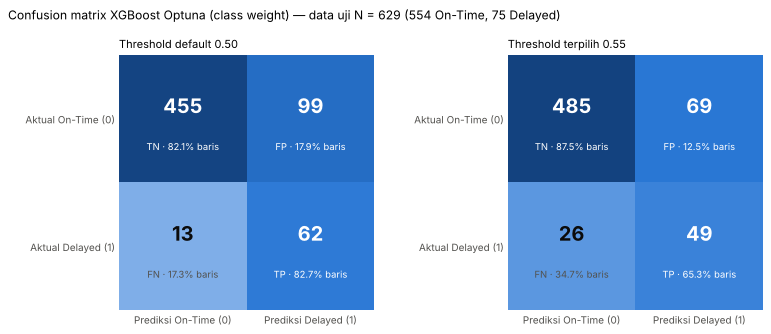

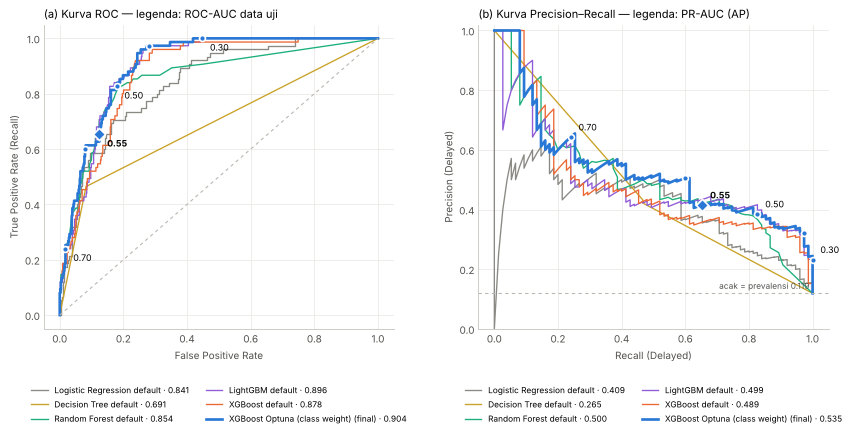

In [16]:
yp_sel = (p_final >= THR).astype(int)
print(classification_report(y_test, yp_sel, digits=4, target_names=["On-Time (0)", "Delayed (1)"]))
RES["final_test"] = {"thr_050": test_eval(final_pipe, 0.5), "thr_sel": test_eval(final_pipe, THR),
                     "brier": brier_score_loss(y_test, p_final),
                     "report_sel": classification_report(y_test, yp_sel, output_dict=True,
                                                         target_names=["On-Time (0)", "Delayed (1)"])}
# Gambar 3.7 — heatmap confusion matrix (0.50 vs terpilih)
blues = matplotlib.colors.LinearSegmentedColormap.from_list("b", ["#eef4fc", "#9cc1ee", "#2a78d6", "#123f7a"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, t, ttl in [(axes[0], 0.50, "Threshold default 0.50"), (axes[1], THR, f"Threshold terpilih {THR:.2f}")]:
    cm = confusion_matrix(y_test, (p_final >= t).astype(int))
    ax.imshow(np.log1p(cm), cmap=blues, vmin=0, vmax=np.log1p(560))
    lab_ = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            v = cm[i, j]; dark = np.log1p(v) > np.log1p(560) * 0.55
            ax.text(j, i - 0.1, f"{v}", ha="center", va="center", fontsize=18, fontweight="bold",
                    color="white" if dark else INK)
            ax.text(j, i + 0.22, f"{lab_[i][j]} · {v/cm[i].sum()*100:.1f}% baris", ha="center", va="center",
                    fontsize=8.5, color="white" if dark else INK2)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Prediksi On-Time (0)", "Prediksi Delayed (1)"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Aktual On-Time (0)", "Aktual Delayed (1)"])
    ax.set_title(ttl); ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle(f"Confusion matrix {FINAL_NAME} — data uji N = 629 (554 On-Time, 75 Delayed)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/gambar3_7_confusion_matrix.png", facecolor=SURF); plt.show()

# Gambar 3.6 — ROC & PR: 5 model default + model final
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.6))
COLS = {"Logistic Regression (Baseline)": "#8a8983", "Decision Tree (Baseline)": "#c9a227",
        "Random Forest (Ensemble)": C3, "LightGBM (Ensemble)": "#8f5bd6", "XGBoost (Ensemble)": C2}
for name, p in p_test_default.items():
    fpr, tpr, _ = roc_curve(y_test, p); pr, rc, _ = precision_recall_curve(y_test, p)
    lbl = name.split(" (")[0] + " default"
    a1.plot(fpr, tpr, color=COLS[name], lw=1.2, label=f"{lbl} · {roc_auc_score(y_test, p):.3f}")
    a2.plot(rc, pr, color=COLS[name], lw=1.2, label=f"{lbl} · {average_precision_score(y_test, p):.3f}")
fpr, tpr, _ = roc_curve(y_test, p_final); pr, rc, _ = precision_recall_curve(y_test, p_final)
a1.plot(fpr, tpr, color=C1, lw=2.4, label=f"{FINAL_NAME} (final) · {roc_auc_score(y_test, p_final):.3f}")
a2.plot(rc, pr, color=C1, lw=2.4, label=f"{FINAL_NAME} (final) · {average_precision_score(y_test, p_final):.3f}")
a1.plot([0, 1], [0, 1], color="#b9b8b1", lw=1, ls=(0, (3, 3)))
a2.axhline(y_test.mean(), color="#b9b8b1", lw=1, ls=(0, (3, 3)))
a2.text(0.99, y_test.mean() + 0.015, f"acak = prevalensi {y_test.mean():.3f}", ha="right", fontsize=7.5, color=INK2)
for t in [0.30, 0.40, 0.50, 0.60, 0.70, THR]:
    yp = (p_final >= t).astype(int); r_ = recall_score(y_test, yp); pp_ = precision_score(y_test, yp, zero_division=0)
    fpr_ = ((yp == 1) & (y_test == 0)).sum() / (y_test == 0).sum(); sel = abs(t - THR) < 1e-9
    for ax, xy in [(a1, (fpr_, r_)), (a2, (r_, pp_))]:
        ax.scatter(*xy, s=60 if sel else 28, color=C1, edgecolor="white", lw=1.5, zorder=5, marker="D" if sel else "o")
        if t in (0.30, 0.50, 0.70) or sel:
            ax.annotate(f"{t:.2f}", xy, xytext=(7, -11 if ax is a1 else 6), textcoords="offset points", fontsize=8,
                        fontweight="bold" if sel else "normal")
a1.set_xlabel("False Positive Rate"); a1.set_ylabel("True Positive Rate (Recall)")
a1.set_title("(a) Kurva ROC — legenda: ROC-AUC data uji")
a2.set_xlabel("Recall (Delayed)"); a2.set_ylabel("Precision (Delayed)"); a2.set_ylim(0, 1.02)
a2.set_title("(b) Kurva Precision–Recall — legenda: PR-AUC (AP)")
for ax in (a1, a2):
    style_ax(ax); ax.legend(fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout(); fig.savefig("figures/gambar3_6_roc_pr.png", facecolor=SURF, bbox_inches="tight"); plt.show()

## 16. Grafik ambang batas (Gambar 3.5) & riwayat Optuna (Gambar 3.4)

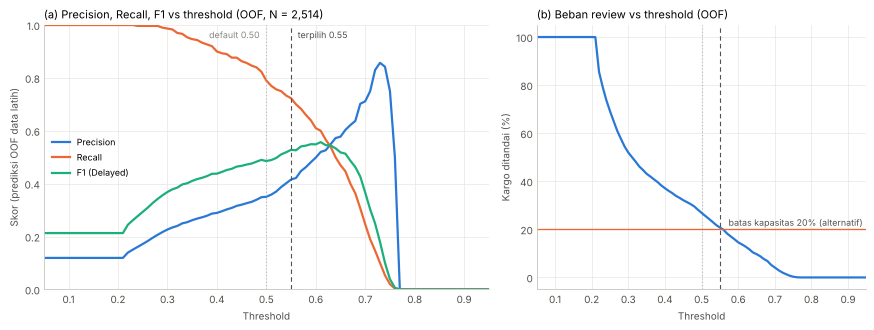

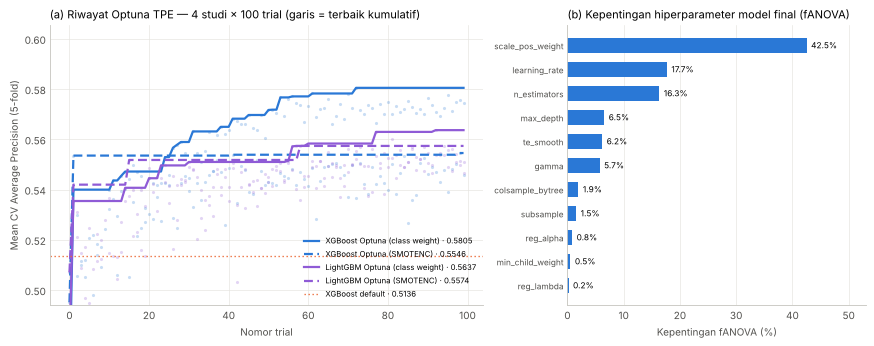

In [17]:
P_ = [precision_score(y_train, (oof >= t).astype(int), zero_division=0) for t in grid]
R_ = [recall_score(y_train, (oof >= t).astype(int)) for t in grid]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
a1.plot(grid, P_, color=C1, lw=2, label="Precision"); a1.plot(grid, R_, color=C2, lw=2, label="Recall")
a1.plot(grid, f1_oof, color=C3, lw=2, label="F1 (Delayed)")
for ax in (a1, a2):
    ax.axvline(THR, color=INK2, lw=1, ls=(0, (4, 3))); ax.axvline(0.5, color="#b9b8b1", lw=1, ls=(0, (1, 2)))
a1.annotate(f"terpilih {THR:.2f}", (THR, 1.0), xytext=(6, -4), textcoords="offset points", fontsize=8, color=INK2, va="top")
a1.annotate("default 0.50", (0.5, 1.0), xytext=(-6, -4), textcoords="offset points", fontsize=8, color="#8a8983", va="top", ha="right")
a1.set_xlabel("Threshold"); a1.set_ylabel("Skor (prediksi OOF data latih)"); a1.set_ylim(0, 1); a1.set_xlim(0.05, 0.95)
a1.set_title(f"(a) Precision, Recall, F1 vs threshold (OOF, N = {len(y_train):,})"); a1.legend(frameon=False, fontsize=8, loc="center left")
a2.plot(grid, share * 100, color=C1, lw=2); a2.axhline(20, color=C2, lw=1.2)
a2.text(0.94, 21.5, "batas kapasitas 20% (alternatif)", ha="right", fontsize=8, color=INK2)
a2.set_xlabel("Threshold"); a2.set_ylabel("Kargo ditandai (%)"); a2.set_xlim(0.05, 0.95)
a2.set_title("(b) Beban review vs threshold (OOF)")
for ax in (a1, a2):
    style_ax(ax)
fig.tight_layout(); fig.savefig("figures/gambar3_5_threshold.png", facecolor=SURF); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.45, 1]})
STY = {"xgb_cw": (C1, "-"), "xgb_smote": (C1, (0, (4, 2))), "lgb_cw": ("#8f5bd6", "-"), "lgb_smote": ("#8f5bd6", (0, (4, 2)))}
for key, (col, ls) in STY.items():
    t_ = STUDIES[key].trials_dataframe(attrs=("number", "value"))
    a1.scatter(t_["number"], t_["value"], s=8, color=col, alpha=0.25, lw=0)
    a1.plot(t_["number"], t_["value"].cummax(), color=col, lw=2, ls=ls, label=f"{LABEL[key]} · {STUDIES[key].best_value:.4f}")
a1.axhline(cmp["XGBoost (Ensemble)"]["cv_ap"], color=C2, lw=1.2, ls=(0, (1, 2)), label=f"XGBoost default · {cmp['XGBoost (Ensemble)']['cv_ap']:.4f}")
lo = min(STUDIES[k].trials_dataframe()["value"].quantile(0.05) for k in STUDIES)
a1.set_ylim(max(lo - 0.01, 0.35), max(STUDIES[k].best_value for k in STUDIES) + 0.025)
a1.set_xlabel("Nomor trial"); a1.set_ylabel("Mean CV Average Precision (5-fold)")
a1.set_title("(a) Riwayat Optuna TPE — 4 studi × 100 trial (garis = terbaik kumulatif)")
a1.legend(frameon=False, fontsize=7, loc="lower right")
imp = pd.Series(RES[f"optuna_{FINAL_KEY}"]["importance"]).sort_values()
a2.barh(imp.index, imp.values * 100, color=C1, height=0.62)
for i, v in enumerate(imp.values * 100):
    a2.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=7.5)
a2.set_xlim(0, imp.max() * 100 * 1.25); a2.set_xlabel("Kepentingan fANOVA (%)")
a2.set_title("(b) Kepentingan hiperparameter model final (fANOVA)"); a2.tick_params(axis="y", labelsize=7.5)
for ax in (a1, a2):
    style_ax(ax)
a2.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("figures/gambar3_4_optuna.png", facecolor=SURF); plt.show()

## 17. Uji ketahanan: bootstrap 95% CI data uji & validasi kronologis

In [18]:
rng = np.random.default_rng(SEED); yt = y_test.values; boot = {"pr_auc": [], "roc_auc": [], "recall_sel": []}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0:
        continue
    boot["pr_auc"].append(average_precision_score(yt[i], p_final[i])); boot["roc_auc"].append(roc_auc_score(yt[i], p_final[i]))
    boot["recall_sel"].append(recall_score(yt[i], (p_final[i] >= THR).astype(int)))
RES["bootstrap_ci"] = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in boot.items()}
# Validasi kronologis: latih pada 80% cut-off paling awal, uji pada 20% terakhir (konfigurasi final yang sama)
order = pd.to_datetime(lab["Waktu Penutupan Gudang"]).sort_values(kind="stable").index
cut = int(len(order) * 0.8); itr, ite = order[:cut], order[cut:]
chrono = clone(final_pipe).fit(X_all.loc[itr], y_all.loc[itr])
pc = chrono.predict_proba(X_all.loc[ite])[:, 1]
RES["chronological"] = {"train_until": str(pd.to_datetime(lab.loc[itr, "Waktu Penutupan Gudang"]).max().date()),
                        "test_from": str(pd.to_datetime(lab.loc[ite, "Waktu Penutupan Gudang"]).min().date()),
                        "test_delayed_pct": round(float(y_all.loc[ite].mean() * 100), 2),
                        "pr_auc": float(average_precision_score(y_all.loc[ite], pc)),
                        "roc_auc": float(roc_auc_score(y_all.loc[ite], pc))}
print(json.dumps({"bootstrap_ci": RES["bootstrap_ci"], "chronological": RES["chronological"]}, indent=1))

{
 "bootstrap_ci": {
  "pr_auc": [
   0.4255614601616945,
   0.643284765434727
  ],
  "roc_auc": [
   0.8773560461658152,
   0.9272500184304863
  ],
  "recall_sel": [
   0.5466627906976744,
   0.762516447368421
  ]
 },
 "chronological": {
  "train_until": "2026-09-04",
  "test_from": "2026-09-04",
  "test_delayed_pct": 17.97,
  "pr_auc": 0.3846020757965901,
  "roc_auc": 0.7596727721753448
 }
}


## 18. Interpretasi global model final (TreeSHAP bawaan XGBoost/LightGBM, Gambar 3.8)

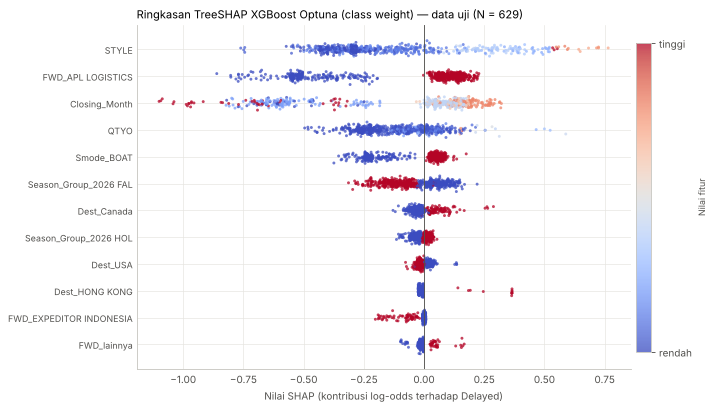

STYLE                    0.284176
FWD_APL LOGISTICS        0.255083
Closing_Month            0.254004
QTYO                     0.146421
Smode_BOAT               0.103759
Season_Group_2026 FAL    0.086307
Dest_Canada              0.032961
Season_Group_2026 HOL    0.024578
Dest_USA                 0.018506
Dest_HONG KONG           0.013671
dtype: float32

In [19]:
Z = final_pipe[:-1].transform(X_test); names = list(final_pipe.named_steps["prep"].get_feature_names_out())
clf = final_pipe.named_steps["clf"]
if fam == "xgb":
    contrib = clf.get_booster().predict(xgboost.DMatrix(np.asarray(Z, float), feature_names=names), pred_contribs=True)[:, :-1]
else:
    contrib = clf.predict(np.asarray(Z, float), pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(contrib).mean(0), index=names).sort_values(ascending=False)
RES["shap_top10"] = shap_imp.head(10).round(4).to_dict()
top = shap_imp.head(12).index[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
for i, f_ in enumerate(top):
    j = names.index(f_); v = np.asarray(Z, float)[:, j]
    vn = (v - np.nanmin(v)) / (np.nanmax(v) - np.nanmin(v) + 1e-9)
    jitter = np.random.default_rng(i).normal(0, 0.09, len(v))
    sc = ax.scatter(contrib[:, j], i + jitter, c=vn, cmap="coolwarm", s=7, alpha=0.75, lw=0, vmin=0, vmax=1)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top, fontsize=8)
ax.set_xlabel("Nilai SHAP (kontribusi log-odds terhadap Delayed)")
ax.set_title(f"Ringkasan TreeSHAP {FINAL_NAME} — data uji (N = 629)")
cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.01); cb.set_ticks([0, 1]); cb.set_ticklabels(["rendah", "tinggi"])
cb.set_label("Nilai fitur", fontsize=8)
style_ax(ax); fig.tight_layout(); fig.savefig("figures/gambar3_8_shap.png", facecolor=SURF); plt.show()
shap_imp.head(10)

## 19. Serialisasi model final (`.joblib`) & demo inferensi data mentah ERP

In [20]:
import joblib
deploy = ImbPipeline([("fe", FunctionTransformer(npp.build_features)), *final_pipe.steps])   # sampler dilewati saat prediksi
raw_test = lab.loc[X_test.index, npp.RAW_INPUT]
assert np.allclose(deploy.predict_proba(raw_test)[:, 1], p_final)
bundle = {"pipeline": deploy, "threshold": THR, "review_zone": (THR, HI), "capacity20_threshold": THR_CAP, "model": FINAL_NAME,
          "features": npp.FEATURES, "best_params": STUDIES[FINAL_KEY].best_params, "versions": VERSIONS,
          "known_styles": sorted(X_train.STYLE.unique().tolist()),
          "qtyo_range": [float(X_train.QTYO.min()), float(X_train.QTYO.max())],
          "options": {c: sorted(X_train[c].dropna().unique().tolist()) for c in npp.CAT_COLS}}
joblib.dump(bundle, "model_final_uts.joblib", compress=3)
B = joblib.load("model_final_uts.joblib")
contoh = pd.DataFrame([{"Contrac date": "2026-08-25", "Waktu Penutupan Gudang": "2026-09-08", "STYLE": "1182201",
                        "QTYO": 2500, "Dest": "Canada", "Smode": "BOAT", "Season": "2026 HOL", "FWD": "APL LOGISTICS"}])
t0 = time.perf_counter(); pz = B["pipeline"].predict_proba(contoh)[0, 1]; lat = (time.perf_counter() - t0) * 1000
RES["deploy"] = {"size_kb": round(os.path.getsize("model_final_uts.joblib") / 1024, 1), "demo_p": float(pz),
                 "demo_label": "Delayed" if pz >= THR else "On-Time", "latency_ms_single": round(lat, 2)}
print(json.dumps(RES["deploy"], indent=1))

{
 "size_kb": 87.0,
 "demo_p": 0.7622008919715881,
 "demo_label": "Delayed",
 "latency_ms_single": 11.36
}


## 20. Simpan seluruh hasil numerik (dipakai untuk menyusun naskah Bab III)

In [21]:
json.dump(RES, open("results/uts_results.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Selesai. Model final:", FINAL_NAME, "| threshold:", THR, "| file: results/uts_results.json, figures/, model_final_uts.joblib")

Selesai. Model final: XGBoost Optuna (class weight) | threshold: 0.55 | file: results/uts_results.json, figures/, model_final_uts.joblib
